# ATP Conformer Analysis

Downloads all ATP-containing structures from the PDB, extracts conformers, filters
incomplete molecules, aligns to a reference, clusters by RMSD (Butina), and exports
representative SDF files.

---

**Checkpointing.** Each slow step saves its output to disk. Re-running a cell will
load from disk if the file already exists — delete the file to force recomputation.

| Step | Checkpoint file | Approx. time |
|---|---|---|
| Download + extract | `atp_conformers_raw.sdf` | 20–40 min (first run) |
| RMSD matrix | `rmsd_matrix_filtered.npy` | 2–6 h for ~8 k structures |
| 2D embedding | `embedding_mds.npy` | 5–10 min |

> **Existing data?** If you already have `rmsd_matrix.npy` (computed on unfiltered
> molecules), the RMSD cell will sub-index it automatically and save
> `rmsd_matrix_filtered.npy` — no recomputation needed.

In [1]:
# ─── Parameters — edit before running ─────────────────────────────────────────
OUTPUT_DIR   = 'output'      # data output directory
PLOT_DIR     = 'pictures'    # PNG plots
CUTOFF_A     = 1.5    # Butina RMSD clustering cutoff (Ångström)
N_REPS       = 10     # representative conformers written per cluster SDF
MAX_STRUCTS  = 9999   # cap on PDB structures fetched (9999 = all)
SEED         = 42     # random seed
TEST_MODE    = False  # True = 50 synthetic conformers (quick smoke-test)
SMALL_THRESHOLD = 10  # clusters below this size are grouped as 'small' in plots

In [2]:
%matplotlib inline
import os, json, time, random
from collections import defaultdict, Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import requests
from scipy.sparse.linalg import LinearOperator, eigsh

from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign, rdFMCS
from rdkit.ML.Cluster import Butina

random.seed(SEED)
Path(OUTPUT_DIR).mkdir(exist_ok=True)
Path(PLOT_DIR).mkdir(exist_ok=True)

ATP_SMILES  = ('c1nc(c2c(n1)n(cn2)[C@@H]3[C@@H]([C@@H]([C@H]'
               '(O3)COP(=O)(O)OP(=O)(O)OP(=O)(O)O)O)O)N')
EXPECTED_HA = Chem.MolFromSmiles(ATP_SMILES).GetNumHeavyAtoms()
print(f'Setup OK  |  expected ATP heavy atoms: {EXPECTED_HA}')

Setup OK  |  expected ATP heavy atoms: 31


## Helper functions
Run this cell once — functions are used in all steps below.

In [3]:
def get_atp_pdb_ids(max_results=9999):
    url = 'https://www.ebi.ac.uk/pdbe/api/pdb/compound/in_pdb/ATP'
    resp = requests.get(url, timeout=60)
    resp.raise_for_status()
    atp_data = resp.json().get('ATP', [])
    ids = []
    for item in atp_data:
        if isinstance(item, str):
            ids.append(item.upper())
        elif isinstance(item, dict):
            for key in ('pdb_id', 'entry_id', 'id', 'pdbId'):
                if key in item:
                    ids.append(item[key].upper())
                    break
    return ids[:max_results]


def download_pdb(pdb_id, cache_dir='pdb_cache'):
    os.makedirs(cache_dir, exist_ok=True)
    local = Path(cache_dir) / f'{pdb_id.lower()}.pdb'
    if local.exists():
        return local.read_text()
    resp = requests.get(f'https://files.rcsb.org/download/{pdb_id}.pdb', timeout=30)
    if resp.status_code == 200:
        local.write_text(resp.text)
        return resp.text
    return None


def extract_atp_from_pdb_text(pdb_text, pdb_id):
    atp_lines = [l for l in pdb_text.split('\n')
                 if (l.startswith('HETATM') and l[17:20].strip() == 'ATP')
                 or l.startswith('CONECT') or l.startswith('END')]
    if not atp_lines:
        return []
    groups = defaultdict(list)
    for l in atp_lines:
        if l.startswith('HETATM'):
            groups[f'{l[21]}_{l[22:26].strip()}'].append(l)
    mols = []
    for key, lines in groups.items():
        mol = Chem.MolFromPDBBlock('\n'.join(lines + ['END']),
                                   sanitize=False, removeHs=False)
        if mol and mol.GetNumAtoms() > 5:
            try:
                Chem.SanitizeMol(mol)
                mol.SetProp('_Name', f'{pdb_id}_{key}')
                mols.append(mol)
            except Exception:
                pass
    return mols


def compute_rmsd_matrix(mols):
    N = len(mols)
    mat = np.zeros((N, N))
    for i in range(N):
        if i % 100 == 0:
            print(f'  row {i}/{N}', end='\r')
        for j in range(i+1, N):
            try:
                rms = rdMolAlign.GetBestRMS(mols[i], mols[j])
            except Exception:
                rms = 99.0
            mat[i, j] = mat[j, i] = rms
    print()
    return mat


def cluster_butina(rmsd_matrix, cutoff):
    N = rmsd_matrix.shape[0]
    dist_list = [float(rmsd_matrix[i, j]) for i in range(1, N) for j in range(i)]
    clusters = Butina.ClusterData(dist_list, N, cutoff, isDistData=True, reordering=True)
    return sorted(clusters, key=len, reverse=True)


def build_reference_atp():
    mol = Chem.MolFromSmiles(ATP_SMILES)
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol, randomSeed=42)
    AllChem.MMFFOptimizeMolecule(mol)
    return Chem.RemoveHs(mol)


def make_alignment_pattern(ref_mol, probe_mol):
    mcs = rdFMCS.FindMCS(
        [probe_mol, ref_mol],
        atomCompare=rdFMCS.AtomCompare.CompareElements,
        bondCompare=rdFMCS.BondCompare.CompareAny,
        timeout=10,
    )
    pattern   = Chem.MolFromSmarts(mcs.smartsString)
    ref_match = ref_mol.GetSubstructMatch(pattern)
    return pattern, ref_match


def align_mol(mol, ref_mol, pattern, ref_match):
    probe_match = mol.GetSubstructMatch(pattern)
    if not probe_match or not ref_match:
        return False
    try:
        rdMolAlign.AlignMol(mol, ref_mol, atomMap=list(zip(probe_match, ref_match)))
        return True
    except Exception:
        return False


def mds_embedding(rmsd_mat, cache_path):
    cache_path = Path(cache_path)
    if cache_path.exists():
        print(f'  Loading cached embedding from {cache_path}')
        return np.load(cache_path)
    print('  Computing classical MDS (PCoA) — takes 5-10 min for ~8 k points...')
    D2 = rmsd_mat.astype(np.float32) ** 2
    n  = D2.shape[0]
    def matvec(v):
        w  = v - v.mean()
        Bv = D2 @ w.astype(np.float32)
        Bv -= Bv.mean()
        return -0.5 * Bv.astype(np.float64)
    B_op = LinearOperator((n, n), matvec=matvec, dtype=np.float64)
    vals, vecs = eigsh(B_op, k=2, which='LM', tol=1e-4, maxiter=500)
    order = np.argsort(vals)[::-1]
    embedding = vecs[:, order] * np.sqrt(np.maximum(vals[order], 0))
    np.save(cache_path, embedding)
    print(f'  Saved to {cache_path}')
    return embedding


print('Helper functions loaded.')

Helper functions loaded.


---
## Step 1 — Fetch ATP-containing PDB IDs
Queries the PDBe REST API for all structures that contain the ligand ATP.
In test mode, this step is skipped and 50 synthetic conformers are generated instead.

In [4]:
if TEST_MODE:
    pdb_ids = []
    print('TEST MODE — will generate 50 synthetic conformers, skipping PDB download.')
else:
    print('Fetching ATP PDB IDs from PDBe...')
    pdb_ids = get_atp_pdb_ids(MAX_STRUCTS)
    print(f'  {len(pdb_ids)} structures found.')

Fetching ATP PDB IDs from PDBe...
  3627 structures found.


---
## Step 2 — Download & Extract ATP Conformers
Downloads each PDB file (cached locally in `pdb_cache/`) and extracts all ATP
HETATM records. Structures with multiple ATP copies contribute one molecule each.

**Checkpoint:** result is saved to `atp_conformers_raw.sdf` and reloaded on
subsequent runs — no re-downloading needed.

In [5]:
RAW_SDF = f'{OUTPUT_DIR}/atp_conformers_raw.sdf'

if TEST_MODE:
    mol_h = Chem.AddHs(Chem.MolFromSmiles(ATP_SMILES))
    cids  = AllChem.EmbedMultipleConfs(mol_h, numConfs=50, randomSeed=SEED)
    mols  = []
    for cid in cids:
        m = Chem.RWMol(mol_h)
        m.SetProp('_Name', f'synthetic_{cid}')
        mols.append(m.GetMol())
    print(f'Generated {len(mols)} synthetic conformers.')

elif Path(RAW_SDF).exists():
    print(f'Loading from checkpoint: {RAW_SDF}')
    mols = [m for m in Chem.SDMolSupplier(RAW_SDF, removeHs=False) if m]
    print(f'  Loaded {len(mols):,} molecules.')

else:
    print(f'Extracting ATP from {len(pdb_ids)} PDB structures...')
    mols = []
    for i, pdb_id in enumerate(pdb_ids):
        if i % 200 == 0:
            print(f'  {i}/{len(pdb_ids)} processed  |  {len(mols)} molecules so far')
        pdb_text = download_pdb(pdb_id)
        if pdb_text:
            mols.extend(extract_atp_from_pdb_text(pdb_text, pdb_id))
        time.sleep(0.05)  # be polite to RCSB
    print(f'\n  Extracted {len(mols):,} ATP conformers from {len(pdb_ids)} structures.')
    print(f'  Saving checkpoint to {RAW_SDF}...')
    with Chem.SDWriter(RAW_SDF) as w:
        w.SetKekulize(False)
        for mol in mols:
            w.write(mol)
    print('  Done.')

print(f'\nTotal conformers available: {len(mols):,}')

Loading from checkpoint: output/atp_conformers_raw.sdf
  Loaded 8,793 molecules.

Total conformers available: 8,793


---
## Step 3 — Filter Incomplete Molecules & Align to Reference

**Filter:** keep only conformers with exactly the expected number of heavy atoms (31
for ATP). Incomplete records from the PDB — missing phosphate oxygens, truncated
adenine, etc. — are discarded.

**Align:** all surviving molecules are superposed onto an MMFF-optimised ATP reference
using the maximum common substructure (MCS). This puts every conformer in the same
coordinate frame for visual comparison.

In [6]:
# ── Filter ──────────────────────────────────────────────────────────────────
filtered_indices = [i for i, m in enumerate(mols) if m.GetNumHeavyAtoms() == EXPECTED_HA]
mols_filtered    = [mols[i] for i in filtered_indices]

n_excl = len(mols) - len(mols_filtered)
print(f'Heavy atom filter ({EXPECTED_HA} expected):')
print(f'  Kept:     {len(mols_filtered):,}')
print(f'  Excluded: {n_excl:,} ({n_excl/len(mols)*100:.1f}%)')

excl_counts = Counter(mols[i].GetNumHeavyAtoms()
                      for i in range(len(mols)) if i not in set(filtered_indices))
print(f'  HA distribution of excluded: {dict(sorted(excl_counts.items()))}')

# ── Align ───────────────────────────────────────────────────────────────────
print('\nAligning to reference ATP...')
ref_mol = build_reference_atp()
pattern, ref_match = make_alignment_pattern(ref_mol, mols_filtered[0])
print(f'  MCS: {pattern.GetNumAtoms()} atoms, {pattern.GetNumBonds()} bonds')

n_aligned = sum(align_mol(m, ref_mol, pattern, ref_match) for m in mols_filtered)
print(f'  Aligned: {n_aligned}/{len(mols_filtered)}')
if n_aligned < len(mols_filtered):
    print(f'  ({len(mols_filtered)-n_aligned} molecules could not be aligned — kept unaligned)')

Heavy atom filter (31 expected):
  Kept:     8,793
  Excluded: 0 (0.0%)
  HA distribution of excluded: {}

Aligning to reference ATP...
  MCS: 31 atoms, 33 bonds
  Aligned: 8791/8793
  (2 molecules could not be aligned — kept unaligned)


---
## Step 4 — Pairwise RMSD Matrix

Computes all-vs-all heavy-atom RMSD after optimal superposition (`GetBestRMS`).
This is the most expensive step: O(N²) pairwise alignments.

**Checkpoint logic (automatic):**
1. If `rmsd_matrix_filtered.npy` exists with the right shape → load it.
2. Else if `rmsd_matrix.npy` exists (older unfiltered run) → sub-index to the filtered
   molecules and save as `rmsd_matrix_filtered.npy`.
3. Otherwise → compute from scratch (hours) and save.

In [7]:
N = len(mols_filtered)
RMSD_FILTERED = f'{OUTPUT_DIR}/rmsd_matrix_filtered.npy'
RMSD_FULL     = f'{OUTPUT_DIR}/rmsd_matrix.npy'

if Path(RMSD_FILTERED).exists():
    rmsd_mat = np.load(RMSD_FILTERED)
    assert rmsd_mat.shape == (N, N), (
        f'Shape mismatch: matrix is {rmsd_mat.shape} but expected ({N}, {N}). '
        f'Delete {RMSD_FILTERED} to recompute.')
    print(f'Loaded filtered RMSD matrix from {RMSD_FILTERED}  ({rmsd_mat.shape})')

elif Path(RMSD_FULL).exists():
    rmsd_full = np.load(RMSD_FULL)
    if rmsd_full.shape == (N, N):
        rmsd_mat = rmsd_full
        print(f'Loaded RMSD matrix from {RMSD_FULL}  ({rmsd_mat.shape})')
    else:
        print(f'Found {rmsd_full.shape} matrix — sub-indexing to ({N}, {N}) filtered molecules...')
        idx = np.array(filtered_indices)
        rmsd_mat = rmsd_full[np.ix_(idx, idx)]
        np.save(RMSD_FILTERED, rmsd_mat)
        print(f'  Saved sub-indexed matrix to {RMSD_FILTERED}')

else:
    print(f'Computing {N}x{N} RMSD matrix from scratch...')
    print('  Warning: this can take several hours for thousands of molecules.')
    rmsd_mat = compute_rmsd_matrix(mols_filtered)
    np.save(RMSD_FILTERED, rmsd_mat)
    print(f'  Saved to {RMSD_FILTERED}')

print(f'RMSD matrix shape: {rmsd_mat.shape}  |  max RMSD: {rmsd_mat.max():.2f} Å')

Loaded filtered RMSD matrix from output/rmsd_matrix_filtered.npy  ((8793, 8793))
RMSD matrix shape: (8793, 8793)  |  max RMSD: 99.00 Å


---
## Step 5 — Cluster with Butina Algorithm

Butina clustering groups conformers such that every cluster member is within
`CUTOFF_A` Å RMSD of the cluster centroid. Clusters are sorted by size (largest first).

In [8]:
print(f'Clustering {N} conformers at {CUTOFF_A} Å cutoff...')
clusters = cluster_butina(rmsd_mat, CUTOFF_A)
print(f'  {len(clusters)} clusters found')
print(f'  Largest cluster: {len(clusters[0]):,} ({len(clusters[0])/N*100:.1f}%)')
print()

# Summary table for the 10 biggest clusters
print(f'{"Rank":>4}  {"Size":>6}  {"% total":>8}  Centroid name')
print('-' * 55)
for i, cl in enumerate(clusters[:10]):
    centroid = mols_filtered[cl[0]]
    name = centroid.GetProp('_Name') if centroid.HasProp('_Name') else str(cl[0])
    print(f'{i+1:>4}  {len(cl):>6,}  {len(cl)/N*100:>7.1f}%  {name}')

Clustering 8793 conformers at 1.5 Å cutoff...


  82 clusters found
  Largest cluster: 4,871 (55.4%)

Rank    Size   % total  Centroid name
-------------------------------------------------------
   1   4,871     55.4%  6RDR_T_1001
   2     944     10.7%  5FWP_B_1692
   3     576      6.6%  9VLN_4_902
   4     520      5.9%  4EAH_F_403
   5     447      5.1%  1KH2_B_1510
   6     317      3.6%  7Y59_A_901
   7     188      2.1%  8V48_A_501
   8     133      1.5%  3RGL_A_401
   9     108      1.2%  8DTB_A_5103
  10      84      1.0%  8PPD_B_505


---
## Step 6 — Cluster Size Distribution

Bar chart of conformers per cluster. Clusters with fewer than `SMALL_THRESHOLD`
members are aggregated into a single 'small clusters' bar.

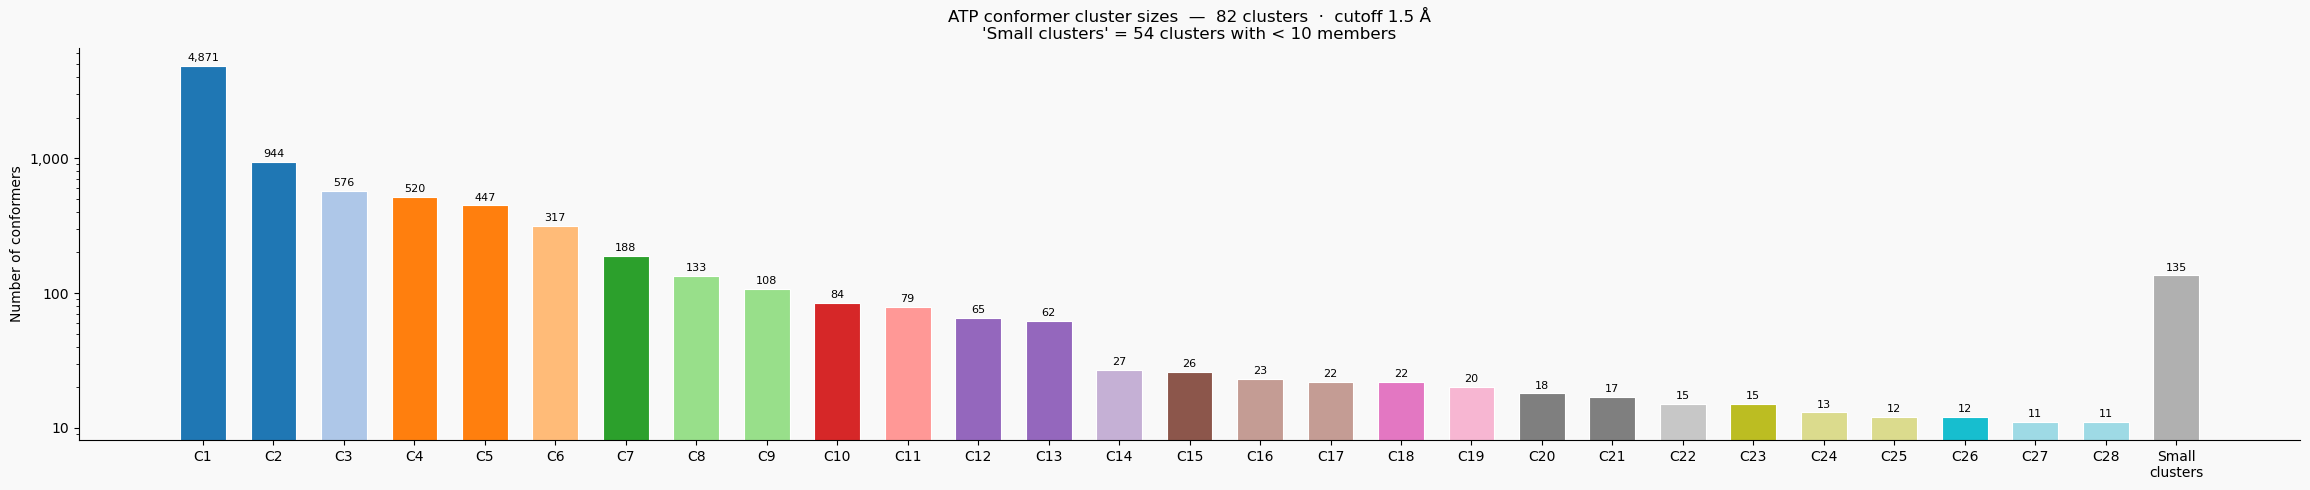

In [9]:
sizes     = [len(cl) for cl in clusters]
big_bars  = [(i+1, s) for i, s in enumerate(sizes) if s >= SMALL_THRESHOLD]
small_tot = sum(s for s in sizes if s < SMALL_THRESHOLD)
n_small   = sum(1 for s in sizes if s < SMALL_THRESHOLD)

n_big  = len(big_bars)
cmap   = plt.get_cmap('tab10' if n_big <= 10 else 'tab20')
labels = [f'C{r}' for r, _ in big_bars] + ['Small\nclusters']
values = [s for _, s in big_bars] + [small_tot]
colors = [cmap(i / max(n_big-1, 1)) for i in range(n_big)] + ['#b0b0b0']

fig, ax = plt.subplots(figsize=(max(8, len(labels)*0.8), 5))
fig.patch.set_facecolor('#f9f9f9'); ax.set_facecolor('#f9f9f9')
bars = ax.bar(labels, values, color=colors, edgecolor='white', linewidth=0.8, width=0.65)
for bar, val in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.05,
            f'{val:,}', ha='center', va='bottom', fontsize=8)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylabel('Number of conformers')
ax.set_title(
    f'ATP conformer cluster sizes  —  {len(clusters)} clusters  ·  cutoff {CUTOFF_A} Å\n'
    f"'Small clusters' = {n_small} clusters with < {SMALL_THRESHOLD} members"
)
for spine in ['top','right']: ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/cluster_sizes_bar.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 10 — Energy-Minimised Representative per Cluster

For each cluster, every member (up to `MINIMISE_CAP` for large clusters) is
energy-minimised with **MMFF94** (RDKit). The conformer with the lowest post-
minimisation energy becomes the cluster's canonical representative.

**Why MMFF94?**  
All cluster members are the same molecule in similar geometries, so *relative*
MMFF94 energies reliably identify the least-strained local minimum within each
basin. If you need cross-cluster energy comparisons or better phosphate
treatment, re-run minimisation with GFN2-xTB (`xtb-python`) — the SDF output
format here is compatible.

**Checkpoint:** results saved to `cluster_minimised/` — delete to recompute.

**Output SDF properties per molecule:**
- `MMFF94_Energy_kcal_mol` — post-minimisation energy
- `MMFF94_Status` — `0` = converged, `1` = not fully converged, `-1` = failed
- `Is_EnergyMin_Rep` — `1` for the lowest-energy conformer in its cluster
- `Cluster_Rank`, `Cluster_Size`, `Conformer_Index` (carried over)


In [13]:
# ── Parameters ──────────────────────────────────────────────────────────────
MINIMISE_CAP  = None   # max members to minimise per cluster (None = all)
MMFF_MAX_ITER = 1000  # MMFF94 iteration cap

# ── Helper ──────────────────────────────────────────────────────────────────
# PDB-extracted molecules carry no bond orders; assign from SMILES template
# so MMFF94 can type atoms correctly (phosphate P=O, aromatic rings, etc.)
_ATP_TEMPLATE = Chem.MolFromSmiles(ATP_SMILES)

def minimise_mmff94(mol, max_iters=MMFF_MAX_ITER):
    """Return (minimised heavy-atom mol, energy_kcal, status_code).
    status: 0=converged, 1=not converged, -1=setup failed."""
    mol_noh = Chem.RemoveHs(mol)
    try:
        mol_noh = AllChem.AssignBondOrdersFromTemplate(_ATP_TEMPLATE, mol_noh)
    except Exception:
        pass  # keep original if template matching fails
    mol_h = Chem.AddHs(mol_noh, addCoords=True)
    props = AllChem.MMFFGetMoleculeProperties(mol_h, mmffVariant='MMFF94')
    if props is not None:
        ff = AllChem.MMFFGetMoleculeForceField(mol_h, props)
        if ff is not None:
            status = ff.Minimize(maxIts=max_iters)  # 0=converged, 1=not converged
            energy = ff.CalcEnergy()
            return Chem.RemoveHs(mol_h), energy, status
    # Fallback: UFF handles missing bond orders (less accurate but always works)
    ff = AllChem.UFFGetMoleculeForceField(mol_h)
    if ff is None:
        return mol, None, -1
    status = ff.Minimize(maxIts=max_iters)
    energy = ff.CalcEnergy()
    return Chem.RemoveHs(mol_h), energy, status

# ── Main loop ───────────────────────────────────────────────────────────────
min_dir = Path(OUTPUT_DIR) / 'cluster_minimised'
min_dir.mkdir(exist_ok=True)

summary_rows = []

for ci, cl in enumerate(clusters):
    rank = ci + 1
    sdf_path = min_dir / f'cluster_{rank:02d}_minimised.sdf'

    if sdf_path.exists():
        print(f'  cluster_{rank:02d}:  loaded from checkpoint')
        continue

    # cap how many members we minimise for very large clusters
    candidates = list(cl)
    if MINIMISE_CAP and len(candidates) > MINIMISE_CAP:
        random.shuffle(candidates)
        candidates = candidates[:MINIMISE_CAP]

    results = []  # (energy, status, mol)
    n_failed = 0
    for idx in candidates:
        mol_in  = Chem.RWMol(mols_filtered[idx])  # work on a copy
        mol_min, energy, status = minimise_mmff94(mol_in)
        if status == -1:
            n_failed += 1
            continue
        # carry over source name
        if mols_filtered[idx].HasProp('_Name'):
            mol_min.SetProp('_Name', mols_filtered[idx].GetProp('_Name'))
        mol_min.SetProp('Cluster_Rank',           str(rank))
        mol_min.SetProp('Cluster_Size',           str(len(cl)))
        mol_min.SetProp('Conformer_Index',        str(idx))
        mol_min.SetProp('MMFF94_Energy_kcal_mol', f'{energy:.4f}')
        mol_min.SetProp('MMFF94_Status',          str(status))
        mol_min.SetProp('Is_EnergyMin_Rep',       '0')
        results.append((energy, status, mol_min))

    if not results:
        print(f'  cluster_{rank:02d}:  ALL {n_failed} minimisations failed — skipped')
        continue

    # sort by energy; tag the winner
    results.sort(key=lambda x: x[0])
    best_energy, _, best_mol = results[0]
    best_mol.SetProp('Is_EnergyMin_Rep', '1')

    with Chem.SDWriter(str(sdf_path)) as w:
        w.SetKekulize(False)
        for _, _, mol_out in results:
            w.write(mol_out)

    converged = sum(1 for e, s, _ in results if s == 0)
    print(
        f'  cluster_{rank:02d}:  {len(results)} minimised  '
        f'({converged} converged, {n_failed} failed)  '
        f'|  best = {best_energy:.2f} kcal/mol  '
        f'({best_mol.GetProp("_Name") if best_mol.HasProp("_Name") else "?"})',
    )
    summary_rows.append({
        'cluster_rank':  rank,
        'cluster_size':  len(cl),
        'n_minimised':   len(results),
        'n_converged':   converged,
        'n_failed':      n_failed,
        'best_energy':   round(best_energy, 4),
        'best_name':     best_mol.GetProp('_Name') if best_mol.HasProp('_Name') else '',
    })

# ── Summary table ────────────────────────────────────────────────────────────
if summary_rows:
    print()
    hdr = f'{"Rank":>4}  {"Size":>6}  {"Minimised":>9}  {"Converged":>9}  {"Best (kcal/mol)":>16}  Best conformer'
    print(hdr)
    print('-' * len(hdr))
    for r in summary_rows:
        print(
            f'{r["cluster_rank"]:>4}  {r["cluster_size"]:>6,}  '
            f'{r["n_minimised"]:>9}  {r["n_converged"]:>9}  '
            f'{r["best_energy"]:>16.2f}  {r["best_name"]}'
        )
    with open(f'{OUTPUT_DIR}/minimisation_summary.json', 'w') as f:
        json.dump(summary_rows, f, indent=2)
    print(f'\nSummary saved to {OUTPUT_DIR}/minimisation_summary.json')

print(f'\nDone — SDF files in {min_dir}/')


  cluster_01:  loaded from checkpoint
  cluster_02:  loaded from checkpoint
  cluster_03:  loaded from checkpoint
  cluster_04:  loaded from checkpoint
  cluster_05:  loaded from checkpoint
  cluster_06:  loaded from checkpoint
  cluster_07:  loaded from checkpoint
  cluster_08:  loaded from checkpoint
  cluster_09:  loaded from checkpoint
  cluster_10:  loaded from checkpoint
  cluster_11:  loaded from checkpoint
  cluster_12:  loaded from checkpoint
  cluster_13:  loaded from checkpoint
  cluster_14:  loaded from checkpoint
  cluster_15:  loaded from checkpoint
  cluster_16:  loaded from checkpoint
  cluster_17:  loaded from checkpoint
  cluster_18:  loaded from checkpoint
  cluster_19:  loaded from checkpoint
  cluster_20:  loaded from checkpoint
  cluster_21:  loaded from checkpoint
  cluster_22:  loaded from checkpoint
  cluster_23:  loaded from checkpoint
  cluster_24:  loaded from checkpoint
  cluster_25:  loaded from checkpoint
  cluster_26:  loaded from checkpoint
  cluster_27

---
## Step 9 — Export Top-2 Representatives as Structure CIF + SDF

Reads from `cluster_minimised/`.

For each cluster, picks the **2 lowest MMFF94-energy conformers** (sorted by
`MMFF94_Energy_kcal_mol`). For each representative, the **actual crystallographic
ATP coordinates** are fetched from the source PDB entry and written as a
structure-format CIF with `_atom_site` records, which is what RFdiffusion3 /
atomworks requires. If the source PDB is unavailable the cell falls back to
MMFF94-minimised coordinates in CCD format (legacy).

Outputs:

| File | Contents |
|---|---|
| `rfd3_inputs/all_clusters_top2.sdf` | All top-2 reps in one SDF (bond orders, 3D coords) |
| `rfd3_inputs/cluster_NN_topK_<name>.cif` | Per-conformer structure CIF with `_atom_site` for RFdiffusion3 |

**Structure CIF format** — each file contains:
- `_entry.id` metadata
- `_atom_site` loop with crystallographic xyz from the source PDB

The `label_comp_id` in each CIF is `ATP` (standard CCD code), recognized by RFD3 and RF3.

In [12]:
from rdkit.Chem import rdMolDescriptors
from Bio.PDB.MMCIF2Dict import MMCIF2Dict

# ── CCD CIF writer (fallback when PDB fetch fails) ────────────────────────────

def mol_to_ccd_cif(mol, comp_id='LIG'):
    """PDB CCD-style mmCIF with _chem_comp_atom records.

    Used as fallback only — RFdiffusion3 requires _atom_site format.
    """
    bond_order_map = {
        Chem.rdchem.BondType.SINGLE:   'SING',
        Chem.rdchem.BondType.DOUBLE:   'DOUB',
        Chem.rdchem.BondType.TRIPLE:   'TRIP',
        Chem.rdchem.BondType.AROMATIC: 'AROM',
    }
    if mol.GetNumConformers() == 0:
        raise ValueError(f'{comp_id}: no 3D conformer present')
    conf = mol.GetConformer()

    elem_counts, seen_names, atom_names = {}, set(), []
    for atom in mol.GetAtoms():
        info = atom.GetPDBResidueInfo()
        name = info.GetName().strip() if info else ''
        if not name or name in seen_names:
            elem = atom.GetSymbol()
            n    = elem_counts.get(elem, 0) + 1
            elem_counts[elem] = n
            name = f'{elem}{n}'
            while name in seen_names:
                n += 1
                elem_counts[elem] = n
                name = f'{elem}{n}'
        seen_names.add(name)
        atom_names.append(name)

    formula = rdMolDescriptors.CalcMolFormula(mol)
    lines = [
        f'data_{comp_id}', '#',
        f'_chem_comp.id          {comp_id}',
        f'_chem_comp.name        "{comp_id}"',
        f'_chem_comp.type        non-polymer',
        f'_chem_comp.formula     "{formula}"',
        '#', 'loop_',
        '_chem_comp_atom.comp_id',
        '_chem_comp_atom.atom_id',
        '_chem_comp_atom.type_symbol',
        '_chem_comp_atom.charge',
        '_chem_comp_atom.model_Cartn_x',
        '_chem_comp_atom.model_Cartn_y',
        '_chem_comp_atom.model_Cartn_z',
    ]
    for atom in mol.GetAtoms():
        pos = conf.GetAtomPosition(atom.GetIdx())
        lines.append(
            f'{comp_id} {atom_names[atom.GetIdx()]} {atom.GetSymbol()} '
            f'{atom.GetFormalCharge()} '
            f'{pos.x:.4f} {pos.y:.4f} {pos.z:.4f}'
        )
    lines += [
        '#', 'loop_',
        '_chem_comp_bond.comp_id',
        '_chem_comp_bond.atom_id_1',
        '_chem_comp_bond.atom_id_2',
        '_chem_comp_bond.value_order',
        '_chem_comp_bond.pdbx_aromatic_flag',
    ]
    for bond in mol.GetBonds():
        lines.append(
            f'{comp_id} {atom_names[bond.GetBeginAtomIdx()]} '
            f'{atom_names[bond.GetEndAtomIdx()]} '
            f'{bond_order_map.get(bond.GetBondType(), "SING")} '
            f'{"Y" if bond.GetIsAromatic() else "N"}'
        )
    lines.append('#')
    return '\n'.join(lines)


# ── Structure CIF writer — fetches real PDB crystallographic coordinates ──────

_ATOM_SITE_COLS = [
    'group_PDB', 'id', 'type_symbol', 'label_atom_id', 'label_alt_id',
    'label_comp_id', 'label_asym_id', 'label_entity_id', 'label_seq_id',
    'pdbx_PDB_ins_code', 'Cartn_x', 'Cartn_y', 'Cartn_z',
    'occupancy', 'B_iso_or_equiv', 'auth_seq_id', 'auth_asym_id',
    'pdbx_PDB_model_num',
]

def fetch_pdb_mmcif(pdb_id, cache_dir='pdb_cache'):
    """Download mmCIF from RCSB and cache as <pdb_id>.cif."""
    cif_local = Path(cache_dir) / f'{pdb_id.lower()}.cif'
    if cif_local.exists():
        return cif_local
    url = f'https://files.rcsb.org/download/{pdb_id}.cif'
    resp = requests.get(url, timeout=60)
    resp.raise_for_status()
    cif_local.write_text(resp.text)
    return cif_local


def extract_ligand_structure_cif(mol_name, comp_id, cache_dir='pdb_cache'):
    """
    Fetch the PDB mmCIF for mol_name (format 'PDBID_CHAIN_RESNUM', e.g. '8BTG_D_501')
    and extract the matching ligand residue as a structure-format CIF with an
    _atom_site loop — required by RFdiffusion3 / atomworks.

    comp_id is written as label_comp_id so it matches the 'ligand' field in the
    RFD3 JSON input specification. The original PDB chain letter is preserved as
    label_asym_id / auth_asym_id so it does not conflict with the chain RFD3
    assigns to the designed protein (typically 'A').

    Returns CIF text, or None if the residue cannot be found.
    """
    parts = mol_name.split('_')
    if len(parts) < 3:
        return None
    pdb_id, chain_id, res_num = parts[0].upper(), parts[1], parts[2]

    try:
        cif_path = fetch_pdb_mmcif(pdb_id, cache_dir)
    except Exception as e:
        print(f'    [{pdb_id}] download failed: {e}')
        return None

    d = MMCIF2Dict(str(cif_path))

    auth_chains = d.get('_atom_site.auth_asym_id', [])
    auth_seqs   = d.get('_atom_site.auth_seq_id', [])
    alt_ids     = d.get('_atom_site.label_alt_id', ['.'] * len(auth_chains))
    models      = d.get('_atom_site.pdbx_PDB_model_num', ['1'] * len(auth_chains))

    # Model 1, correct chain + residue, primary alt loc only
    indices = [
        i for i, (ch, seq, alt, m)
        in enumerate(zip(auth_chains, auth_seqs, alt_ids, models))
        if ch == chain_id and seq == res_num and m == '1'
        and alt in ('.', '?', 'A', '')
    ]
    if not indices:
        return None

    n = len(indices)
    cols = {}
    for col in _ATOM_SITE_COLS:
        vals = d.get(f'_atom_site.{col}', [])
        cols[col] = [(vals[i] if i < len(vals) else '.') for i in indices]

    # Override comp_id so it matches the 'ligand' field in the RFD3 JSON spec.
    # Keep label_asym_id / auth_asym_id as the original PDB chain (e.g. 'D') —
    # do NOT normalise to 'A': RFD3 reserves 'A' for the designed protein chain.
    cols['label_comp_id']      = [comp_id] * n
    cols['label_entity_id']    = ['1']     * n
    cols['label_seq_id']       = ['.']     * n
    cols['pdbx_PDB_model_num'] = ['1']     * n
    cols['id']                 = [str(k + 1) for k in range(n)]

    entry_id = f'{pdb_id}_{chain_id}_{res_num}'
    lines = [f'data_{entry_id}', '#', f'_entry.id  {entry_id}', '#', 'loop_']
    for col in _ATOM_SITE_COLS:
        lines.append(f'_atom_site.{col}')
    for i in range(n):
        lines.append(' '.join(str(cols[col][i]) for col in _ATOM_SITE_COLS))
    lines.append('#')
    return '\n'.join(lines)


# ── Load top-2 energy-minimised reps per cluster ─────────────────────────────
min_dir = Path(OUTPUT_DIR) / 'cluster_minimised'
rfd_dir = Path(OUTPUT_DIR) / 'rfd3_inputs'
rfd_dir.mkdir(exist_ok=True)

if not min_dir.exists() or not any(min_dir.glob('*.sdf')):
    raise RuntimeError(
        f'No minimised SDFs in {min_dir}/  —  run Step 10 first.'
    )

_atp_template = Chem.MolFromSmiles(ATP_SMILES)

def _energy(m):
    try:    return float(m.GetProp('MMFF94_Energy_kcal_mol'))
    except: return float('inf')

top2_all = []   # (cluster_rank, pos_1indexed, mol)

for ci, cl in enumerate(clusters):
    rank     = ci + 1
    sdf_path = min_dir / f'cluster_{rank:02d}_minimised.sdf'
    if not sdf_path.exists():
        print(f'  cluster_{rank:02d}:  SDF missing — skipped')
        continue

    mols_min = [m for m in Chem.SDMolSupplier(str(sdf_path), removeHs=False) if m]
    mols_min.sort(key=_energy)
    top2 = mols_min[:2]

    print(f'  cluster_{rank:02d}:  top-2 energies = '
          + ', '.join(f'{_energy(m):.2f}' for m in top2) + ' kcal/mol')

    for pos, mol in enumerate(top2):
        mol.SetProp('Top2_Rank',    str(pos + 1))
        mol.SetProp('Cluster_Rank', str(rank))
        top2_all.append((rank, pos + 1, mol))

        # Assign bond orders from SMILES template so SDF has correct types
        mol_ha = Chem.RemoveHs(mol)
        try:
            mol_bo = AllChem.AssignBondOrdersFromTemplate(_atp_template, mol_ha)
        except Exception:
            mol_bo = mol_ha

        src_name = mol.GetProp('_Name') if mol.HasProp('_Name') else f'cl{rank:02d}'
        comp_id  = 'ATP'   # standard CCD code — recognized by RFD3 and RF3
        cif_path = rfd_dir / f'cluster_{rank:02d}_top{pos + 1}_{src_name}.cif'

        # Fetch real PDB crystallographic coordinates; fall back to minimised CCD if unavailable
        cif_text = extract_ligand_structure_cif(src_name, comp_id)
        if cif_text is None:
            print(f'    {src_name}: PDB structure not available — using minimised coords (CCD format)')
            cif_text = mol_to_ccd_cif(mol_bo, comp_id=comp_id)
        cif_path.write_text(cif_text)

# ── Combined SDF ──────────────────────────────────────────────────────────────
combined_sdf = rfd_dir / 'all_clusters_top2.sdf'
with Chem.SDWriter(str(combined_sdf)) as w:
    w.SetKekulize(False)
    for _r, _p, mol in top2_all:
        w.write(mol)

print(f'\n{len(top2_all)} conformers  →  {combined_sdf}')
print(f'CIF files           →  {rfd_dir}/')

  cluster_01:  top-2 energies = -513.35, -513.35 kcal/mol
  cluster_02:  top-2 energies = -508.69, -508.69 kcal/mol
  cluster_03:  top-2 energies = -513.99, -507.20 kcal/mol
  cluster_04:  top-2 energies = -506.11, -505.51 kcal/mol
  cluster_05:  top-2 energies = -504.74, -504.60 kcal/mol
  cluster_06:  top-2 energies = -513.99, -513.19 kcal/mol
  cluster_07:  top-2 energies = -505.52, -504.97 kcal/mol
  cluster_08:  top-2 energies = -509.96, -507.87 kcal/mol
  cluster_09:  top-2 energies = -502.54, -498.81 kcal/mol
  cluster_10:  top-2 energies = -501.65, -500.75 kcal/mol
  cluster_11:  top-2 energies = -498.05, -496.67 kcal/mol
  cluster_12:  top-2 energies = -500.61, -500.54 kcal/mol
  cluster_13:  top-2 energies = -499.61, -498.78 kcal/mol
  cluster_14:  top-2 energies = -504.46, -495.13 kcal/mol
  cluster_15:  top-2 energies = -502.29, -502.29 kcal/mol
  cluster_16:  top-2 energies = -521.40, -509.25 kcal/mol
  cluster_17:  top-2 energies = -499.71, -493.76 kcal/mol
  cluster_18: 

[07:50:47] WARNING: More than one matching pattern found - picking one

[07:50:47] Explicit valence for atom # 4 P, 6, is greater than permitted


  cluster_35:  top-2 energies = -495.01, -491.74 kcal/mol
  cluster_36:  top-2 energies = -504.95, -503.50 kcal/mol
  cluster_37:  top-2 energies = -485.23, -485.23 kcal/mol
  cluster_38:  top-2 energies = -493.59, -491.74 kcal/mol
  cluster_39:  top-2 energies = -506.70, -494.27 kcal/mol
  cluster_40:  top-2 energies = -494.60, -487.54 kcal/mol
  cluster_41:  top-2 energies = -489.14, -480.83 kcal/mol
  cluster_42:  top-2 energies = -485.88, -485.88 kcal/mol
  cluster_43:  top-2 energies = -499.16, -499.00 kcal/mol
  cluster_44:  top-2 energies = -498.06, -487.15 kcal/mol
  cluster_45:  top-2 energies = -492.76, -487.81 kcal/mol
  cluster_46:  top-2 energies = -491.05, -490.99 kcal/mol
  cluster_47:  top-2 energies = -494.37, -487.32 kcal/mol
  cluster_48:  top-2 energies = -494.37, -494.01 kcal/mol
  cluster_49:  top-2 energies = -490.76, -487.72 kcal/mol
  cluster_50:  top-2 energies = -491.01, -481.42 kcal/mol
  cluster_51:  top-2 energies = -490.55, -483.90 kcal/mol
  cluster_52: 

[07:51:05] WARNING: More than one matching pattern found - picking one

[07:51:05] Explicit valence for atom # 0 P, 6, is greater than permitted
[07:51:05] WARNING: More than one matching pattern found - picking one

[07:51:05] Explicit valence for atom # 0 P, 6, is greater than permitted


  cluster_53:  top-2 energies = -488.88, -488.05 kcal/mol
  cluster_54:  top-2 energies = -487.86, 486.17 kcal/mol


...

  cluster_76:  top-2 energies = -492.52 kcal/mol
  cluster_77:  top-2 energies = 76392.55 kcal/mol


[07:51:20] WARNING: More than one matching pattern found - picking one

[07:51:20] Explicit valence for atom # 4 P, 6, is greater than permitted


  cluster_78:  top-2 energies = -489.84 kcal/mol
  cluster_79:  top-2 energies = -491.98 kcal/mol
  cluster_80:  top-2 energies = -492.02 kcal/mol
  cluster_81:  top-2 energies = -505.86 kcal/mol
  cluster_82:  top-2 energies = 442.38 kcal/mol


[07:51:22] WARNING: More than one matching pattern found - picking one

[07:51:22] Explicit valence for atom # 0 P, 6, is greater than permitted



138 conformers  →  output/rfd3_inputs/all_clusters_top2.sdf
CIF files           →  output/rfd3_inputs/
